# **Project Name**    - Flipkart Customer Service Satisfaction Prediction



##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Team Member  -** Baviya S


# **Project Summary -**

This project examines whether customer satisfaction on Flipkart’s support tickets can be predicted from details the support team already records. The dataset contains 85,907 tickets with 20 columns, and the target is CSAT Score, a rating from 1 to 5. Most ratings are 5 (69%), and only about 1.5% are 2, so the data is heavily imbalanced and accuracy alone would be misleading.

The data was cleaned and prepared in several steps. I checked for duplicates and missing values, and dropped columns that were almost empty, were identifiers, or could leak the answer, such as Customer Remarks, which may be written after the survey. I converted the response and reply timestamps into a response time in hours. I removed 3,128 rows with negative response times, because a reply cannot come before the report, and capped the remaining delays at 24 hours, which affected 2,877 tickets. This left 82,779 tickets for modeling.

Exploratory analysis looked at the data from several angles. Response time was heavily skewed, with a median of about 6 minutes. Slower replies were linked to lower ratings: the median response time was about 21 minutes for CSAT 1 and about 5 minutes for CSAT 5. Average CSAT differed slightly by channel, with Email the lowest at 3.89 against about 4.25 for Inbound and 4.27 for Outcall. Tenure and shift showed small differences, and the issue category “Others” had the highest share of unhappy customers at 34%, compared with about 15% overall. The correlation between response time and CSAT was -0.16, the strongest single link in the data.

Three hypotheses were tested. The Mann-Whitney U test showed that response time differs between CSAT 1 and CSAT 5 (p < 0.001). The Kruskal-Wallis test showed that average CSAT differs across channels and across tenure buckets (both p < 0.001). With this many records, even small differences are statistically significant, so the size of each gap matters as much as the p-value.

The features were prepared for modeling. The categorical columns were one-hot encoded, giving 123 columns. Five overlapping columns with correlation above 0.8 were dropped, leaving 117 inputs. Response time was log-transformed to reduce its skew, and the data was standardized for Logistic Regression. The data was split 80/20 with stratification, so the rare scores appear in both sets.

Two models were built. A Random Forest with class_weight="balanced" was tuned with 3-fold stratified cross-validation, optimizing macro F1. The tuned model reached 52.5% accuracy, a macro F1 of 0.24, and a weighted F1 of 0.54. It was the strongest on score 5 (recall 0.66) and caught 38% of score 1 tickets. A Logistic Regression with balanced class weights reached 36.5% accuracy and a macro F1 of 0.22, but it caught more unhappy customers, with 27% of score 2 tickets against 6% for the Random Forest. Its precision for score 2 was only 0.02, so most of its warnings were false alarms.

Permutation importance showed that no single input strongly drives the Random Forest’s predictions. The largest drop in macro F1 from shuffling one input was about 0.003, so the model relies on many weak, overlapping signals.

The main conclusion is that the current ticket data is not enough for automatic decisions on individual tickets. Neither model predicts the rare scores well. The most realistic use is to rank tickets by risk and send the highest-risk group to a human reviewer. Logistic Regression suits this if reviews are cheap, and the Random Forest suits it if reviews are costly. To improve the models, the next step is to add richer inputs such as customer history, ticket volume, and resolution outcome.

# **GitHub Link -**

https://github.com/Baviyas/flipkart-capstone

# **Problem Statement**


Flipkart’s customer support handles a large volume of tickets across email, inbound calls, and outbound calls. Each ticket ends with a Customer Satisfaction (CSAT) rating from 1 to 5, which shows how customers feel about the service they received. Low ratings signal unhappy customers, who may stop using the platform, so understanding what drives them matters for retention.

This project asks whether a customer’s CSAT score can be predicted from details the support team already records: the channel, the issue category and sub-category, the agent’s team and tenure, the shift, and how long the agent took to reply. If it can, the team could focus attention on tickets that are likely to end in a poor rating.

The task is a classification problem with five classes, and the data is heavily imbalanced, with about 69% of ratings at 5 and only about 1.5% at 2. The goal is to build and evaluate models that predict the CSAT score while handling this imbalance, using metrics that reflect performance on the rare low scores.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [14]:
# Import Libraries
import pandas as pd


### Dataset Loading

In [15]:
# Load Dataset
import pandas as pd

url = "https://raw.githubusercontent.com/Baviyas/flipkart-capstone/refs/heads/main/Customer_support_data.csv"
df = pd.read_csv(url)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (85907, 20)


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset First View

In [16]:
# Dataset First Look
print(df.columns.tolist())
print(df.isnull().sum())

['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']
Unique id                      0
channel_name                   0
category                       0
Sub-category                   0
Customer Remarks           57165
Order_id                   18232
order_date_time            68693
Issue_reported at              0
issue_responded                0
Survey_response_Date           0
Customer_City              68828
Product_category           68711
Item_price                 68701
connected_handling_time    85665
Agent_name                     0
Supervisor                     0
Manager                        0
Tenure Bucket                  0
Agent Shift                    0
CSAT Score                     0
dtyp

### Dataset Rows & Columns count

In [17]:
# Dataset Rows & Columns count
print(df["CSAT Score"].value_counts().sort_index())
print((df["CSAT Score"].value_counts(normalize=True).sort_index() * 100).round(2))

CSAT Score
1    11230
2     1283
3     2558
4    11219
5    59617
Name: count, dtype: int64
CSAT Score
1    13.07
2     1.49
3     2.98
4    13.06
5    69.40
Name: proportion, dtype: float64


### Dataset Information

In [18]:
# Dataset Info
df.info()
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [19]:
# Dataset Duplicate Value Count
df["Issue_reported at"] = pd.to_datetime(df["Issue_reported at"], dayfirst=True, errors="coerce")
df["issue_responded"] = pd.to_datetime(df["issue_responded"], dayfirst=True, errors="coerce")
df["response_time_hours"] = (df["issue_responded"] - df["Issue_reported at"]).dt.total_seconds() / 3600
print(df["response_time_hours"].describe())

count    85907.000000
mean         2.281443
std          9.875476
min        -23.950000
25%          0.033333
50%          0.083333
75%          0.583333
max         95.966667
Name: response_time_hours, dtype: float64


#### Missing Values/Null Values

In [20]:
# Missing Values/Null Values Count
neg = (df["response_time_hours"] < 0).sum()
over_24 = (df["response_time_hours"] > 24).sum()
print("Negative response times:", neg)
print("Over 24 hours:", over_24)
print("Share over 24 hours:", round(over_24 / len(df) * 100, 2), "%")

Negative response times: 3128
Over 24 hours: 2877
Share over 24 hours: 3.35 %


In [21]:
# Visualizing the missing values
# Remove impossible timestamps and cap long delays
df = df[df["response_time_hours"] >= 0].copy()
df["response_time_hours"] = df["response_time_hours"].clip(upper=24)

print("Rows after cleaning:", df.shape)
print(df["response_time_hours"].describe())

Rows after cleaning: (82779, 21)
count    82779.000000
mean         2.217980
std          5.590858
min          0.000000
25%          0.033333
50%          0.100000
75%          0.650000
max         24.000000
Name: response_time_hours, dtype: float64


### What did you know about your dataset?

This dataset has 85,907 customer support tickets and 20 columns. The goal is to predict CSAT Score, the customer’s satisfaction rating. Most ratings are 5 (69%), and very few are 2 (1.5%), so accuracy alone would be misleading. Some columns are almost empty. Customer Remarks is probably written after the survey, so it could give away the answer. I removed 3,128 rows with negative response times because those are errors, and capped the longer ones at 24 hours. That leaves 82,779 rows for modeling.

## ***2. Understanding Your Variables***

In [22]:
# Dataset Columns
print(df.nunique().sort_values())

channel_name                   3
CSAT Score                     5
Agent Shift                    5
Tenure Bucket                  5
Manager                        6
Product_category               9
category                      12
Survey_response_Date          31
Supervisor                    40
Sub-category                  57
connected_handling_time      211
Agent_name                  1371
response_time_hours         1428
Customer_City               1771
Item_price                  2767
order_date_time            13533
Customer Remarks           17637
Issue_reported at          30144
issue_responded            30262
Order_id                   64547
Unique id                  82779
dtype: int64


In [23]:
# Dataset Describe
drop_cols = ["Unique id", "Order_id", "Agent_name", "Customer_City", "Item_price",
             "Customer Remarks", "Survey_response_Date", "Product_category",
             "connected_handling_time", "order_date_time",
             "Issue_reported at", "issue_responded"]
df_model = df.drop(columns=drop_cols)
print(df_model.columns.tolist())
print(df_model.shape)

['channel_name', 'category', 'Sub-category', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score', 'response_time_hours']
(82779, 9)


### Variables Description

The model uses 8 inputs to predict CSAT Score. Seven of them are categories: the channel the ticket came from, the type of issue, the sub-type, the supervisor and manager, how long the agent has worked, and the shift. The only number is response_time_hours, which is how long the agent took to reply. CSAT Score is the target, the rating from 1 to 5

### Check Unique Values for each variable.

In [24]:
# Check Unique Values for each variable.
for col in df_model.select_dtypes(include="object").columns:
    print(col, "->", df_model[col].unique()[:10])

channel_name -> ['Outcall' 'Inbound' 'Email']
category -> ['Product Queries' 'Order Related' 'Returns' 'Cancellation'
 'Shopzilla Related' 'Payments related' 'Refund Related' 'Feedback'
 'Offers & Cashback' 'Onboarding related']
Sub-category -> ['Life Insurance' 'Product Specific Information' 'Installation/demo'
 'Reverse Pickup Enquiry' 'Not Needed' 'Fraudulent User'
 'Exchange / Replacement' 'Missing' 'General Enquiry' 'Return request']
Supervisor -> ['Mason Gupta' 'Dylan Kim' 'Jackson Park' 'Olivia Wang' 'Austin Johnson'
 'Emma Park' 'Aiden Patel' 'Evelyn Kimura' 'Nathan Patel' 'Amelia Tanaka']
Manager -> ['Jennifer Nguyen' 'Michael Lee' 'William Kim' 'John Smith' 'Olivia Tan'
 'Emily Chen']
Tenure Bucket -> ['On Job Training' '>90' '0-30' '31-60' '61-90']
Agent Shift -> ['Morning' 'Evening' 'Split' 'Afternoon' 'Night']


In [25]:
cat_cols = ["channel_name", "category", "Sub-category", "Supervisor",
            "Manager", "Tenure Bucket", "Agent Shift"]

df_encoded = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

print("Shape after encoding:", df_encoded.shape)
print("All numeric:", df_encoded.drop(columns="CSAT Score").dtypes.apply(lambda t: t != object).all())

Shape after encoding: (82779, 123)
All numeric: True


## 3. ***Data Wrangling***

### Data Wrangling Code

In [26]:
# Write your code to make your dataset analysis ready.
cat_cols = ["channel_name", "category", "Sub-category", "Supervisor",
            "Manager", "Tenure Bucket", "Agent Shift"]

df_encoded = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

print("Shape after encoding:", df_encoded.shape)


Shape after encoding: (82779, 123)


### What all manipulations have you done and insights you found?

I checked the unique values in each text column, then converted the 7 text columns into 0/1 columns using one-hot encoding. I used drop_first=True to avoid repeating information. I kept the response_time_hours number as it was. The data now has 82,779 rows and 123 columns, and all inputs are numeric.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

                     response_time_hours  CSAT Score
response_time_hours             1.000000   -0.162749
CSAT Score                     -0.162749    1.000000


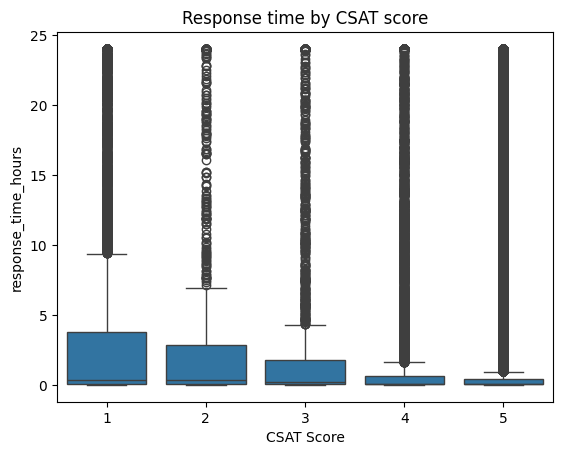

In [27]:
# Chart - 1 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

print(df_model[["response_time_hours", "CSAT Score"]].corr())

sns.boxplot(x="CSAT Score", y="response_time_hours", data=df_model)
plt.title("Response time by CSAT score")
plt.show()

##### 1. Why did you pick the specific chart?

I used a box plot because CSAT Score has only five levels, and a box plot shows the typical response time for each level. It also shows the spread and the outliers, which a simple average would hide.

##### 2. What is/are the insight(s) found from the chart?

Customers who gave a score of 1 usually waited longer for a reply. For score 1, the middle half of replies took up to about 4 hours. For score 5, nearly all replies were answered within about 1 hour. The correlation between response time and CSAT is -0.16, which is a weak negative link. So slow replies are linked to lower ratings, but response time alone won’t predict the score well. Other factors, such as the issue type and the channel, probably matter too.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The chart shows that slower replies go with lower ratings, so Flipkart could focus on speeding up responses in the areas where delays are longest. Faster replies may improve satisfaction and reduce repeat complaints.

There are risks, though. The link is weak (correlation -0.16), so response time alone won’t fix low ratings. Also, pushing agents to reply faster could lower the quality of their answers, which could hurt ratings in other ways. So this insight should be used together with other factors, not on its own.

#### Chart - 2

channel_name
Email      3.89
Inbound    4.25
Outcall    4.27
Name: CSAT Score, dtype: float64


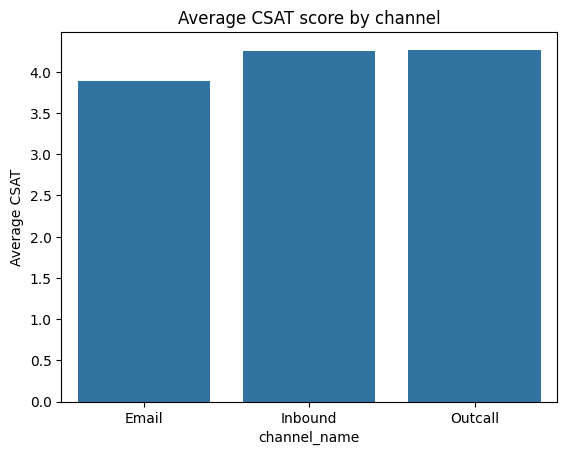

In [28]:
# Chart - 2 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

channel_avg = df_model.groupby("channel_name")["CSAT Score"].mean().round(2).sort_values()
print(channel_avg)

sns.barplot(x=channel_avg.index, y=channel_avg.values)
plt.title("Average CSAT score by channel")
plt.ylabel("Average CSAT")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart to compare the average CSAT score across the three channels. With only three groups, a bar chart makes the differences easy to see.

##### 2. What is/are the insight(s) found from the chart?

Email has the lowest average CSAT score (3.89), while Inbound (4.25) and Outcall (4.27) are close to each other. This suggests that customers who contact Flipkart by email are less satisfied than those who call. The gap is small, so channel is a weak predictor on its own, but it may be worth checking why email tickets get lower ratings, such as slower handling or harder issue types.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. The channel gap is small: email tickets average 3.89, compared with about 4.25 for inbound and 4.27 for outcall. That’s a difference of roughly 0.4 points, so channel alone won’t fix low ratings. But it points to a useful target, since email is the lowest-rated channel and reviewing its process, such as response speed and handling, could lift satisfaction. The main risk is that pushing for faster email replies could lower answer quality, which could hurt ratings in other ways. So any change should be tracked against both speed and quality, and checked against the CSAT scores after the change.

#### Chart - 3

Tenure Bucket
On Job Training    4.13
0-30               4.25
31-60              4.29
61-90              4.34
>90                4.27
Name: CSAT Score, dtype: float64


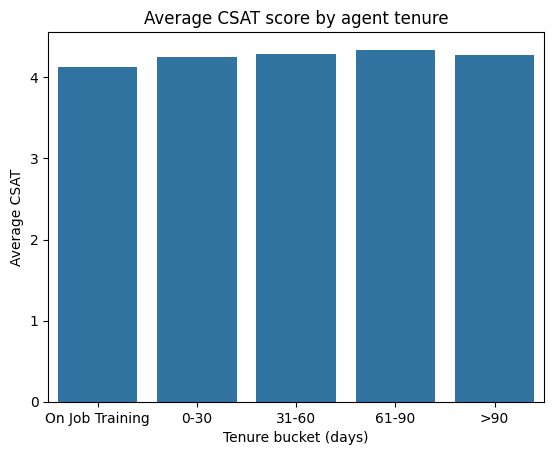

In [29]:
# Chart - 3 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

order = ["On Job Training", "0-30", "31-60", "61-90", ">90"]
tenure_avg = df_model.groupby("Tenure Bucket")["CSAT Score"].mean().round(2).reindex(order)
print(tenure_avg)

sns.barplot(x=tenure_avg.index, y=tenure_avg.values)
plt.title("Average CSAT score by agent tenure")
plt.xlabel("Tenure bucket (days)")
plt.ylabel("Average CSAT")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart because it compares the average score across five tenure groups in order. It makes it easy to see that the newest agents score lowest.

##### 2. What is/are the insight(s) found from the chart?

Agents still in training have the lowest average CSAT (4.13). Scores rise slightly with experience, peaking at 4.34 for agents with 61-90 days. The difference is small, about 0.2 points, so tenure is a weak predictor on its own. Still, it suggests that the first few months of training matter, so coaching new agents may help.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. Improving training for new agents could lift satisfaction, since they score lowest. But the gap is small, so it should be one part of a wider plan. The main risk is spending heavily on training with little return, or pushing new agents to handle tickets faster before they’re ready, which could lower quality and ratings. Also, the chart’s axis starts at zero, which makes the differences look smaller than they are, so the chart is accurate but the gap should be described in numbers, not just visually.

#### Chart - 4

category
Others                3.39
Cancellation          3.99
Product Queries       4.02
Order Related         4.09
Feedback              4.15
Onboarding related    4.21
Offers & Cashback     4.21
Refund Related        4.23
Shopzilla Related     4.30
Returns               4.34
Payments related      4.35
App/website           4.40
Name: CSAT Score, dtype: float64


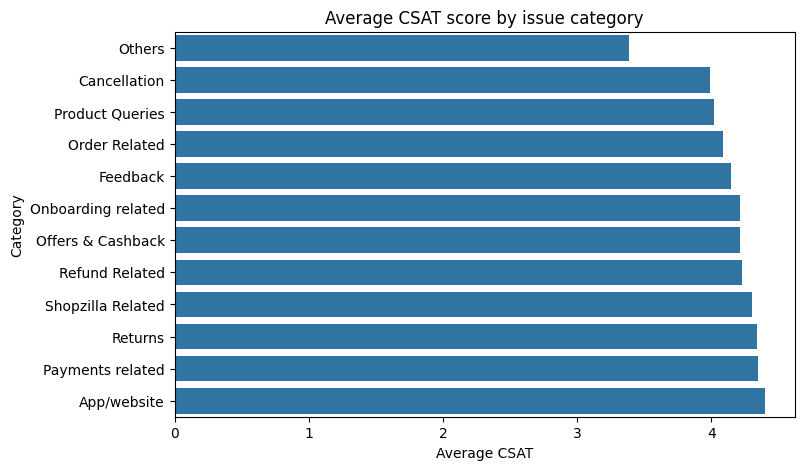

In [30]:
# Chart - 4 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

cat_avg = df_model.groupby("category")["CSAT Score"].mean().round(2).sort_values()
print(cat_avg)

plt.figure(figsize=(8, 5))
sns.barplot(x=cat_avg.values, y=cat_avg.index)
plt.title("Average CSAT score by issue category")
plt.xlabel("Average CSAT")
plt.ylabel("Category")
plt.show()

##### 1. Why did you pick the specific chart?

I used a horizontal bar chart because there are 12 categories, and the names are long. Horizontal bars make the names easy to read, and sorting them shows the lowest-rated categories first.

##### 2. What is/are the insight(s) found from the chart?

“Others” has the lowest average CSAT at 3.39, well below the rest. Cancellation (3.99) and Product Queries (4.02) are the next lowest. App/website has the highest at 4.40. The gap between the lowest and highest is about 1 point, which is large compared with the channel and tenure differences. “Others” is a catch-all group, so it may hide several different problems. The main insight is that cancellations and product questions need a closer look, and “Others” needs to be split into clear categories before anyone can act on it.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this chart is useful for planning. Splitting “Others” into proper categories and improving how cancellations and product queries are handled could lift satisfaction where it is lowest. The risk is that the “Others” group is too vague to act on, so changes made to it could be guesswork. Cancellations also carry a business risk, since a poor experience may push customers away for good. Any changes should be checked against CSAT scores after they are made, so the team can see whether they worked.

#### Chart - 5

Agent Shift
Morning      4.18
Evening      4.27
Afternoon    4.29
Night        4.29
Split        4.43
Name: CSAT Score, dtype: float64


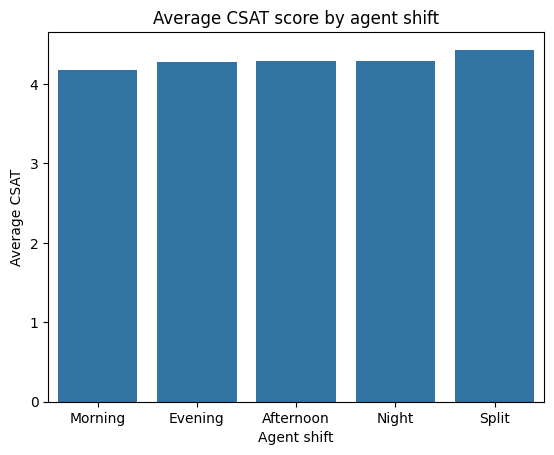

In [31]:
# Chart - 5 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

shift_avg = df_model.groupby("Agent Shift")["CSAT Score"].mean().round(2).sort_values()
print(shift_avg)

sns.barplot(x=shift_avg.index, y=shift_avg.values)
plt.title("Average CSAT score by agent shift")
plt.xlabel("Agent shift")
plt.ylabel("Average CSAT")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart because it compares the average CSAT score across five shifts. It shows at a glance which shift has the lowest and highest scores.

##### 2. What is/are the insight(s) found from the chart?

The Morning shift has the lowest average CSAT (4.18), while Split has the highest (4.43). The gap is about 0.25 points, which is small, so shift alone is a weak predictor of satisfaction. Evening, Afternoon, and Night are all close to each other, around 4.27 to 4.29. The Split shift may have fewer agents or tickets, so its higher score should be checked before it’s treated as a real difference.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. The Morning shift is the lowest-rated, so it could be a good place to review staffing, training, or handling practices. But the gap is small, so this should be one part of a wider plan. The main risk is reading too much into the Split result, since a small group can swing the average. Also, moving agents between shifts to chase higher scores could upset staff and affect service, which could hurt ratings in other ways.

#### Chart - 6

Manager
William Kim        4.11
Olivia Tan         4.11
Jennifer Nguyen    4.15
Michael Lee        4.26
John Smith         4.27
Emily Chen         4.38
Name: CSAT Score, dtype: float64


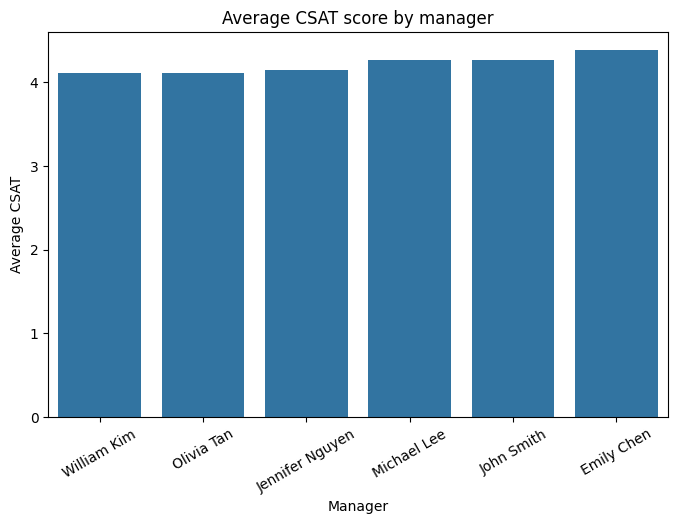

In [32]:
# Chart - 6 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

manager_avg = df_model.groupby("Manager")["CSAT Score"].mean().round(2).sort_values()
print(manager_avg)

plt.figure(figsize=(8, 5))
sns.barplot(x=manager_avg.index, y=manager_avg.values)
plt.title("Average CSAT score by manager")
plt.xlabel("Manager")
plt.ylabel("Average CSAT")
plt.xticks(rotation=30)
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart because it compares the average CSAT score across six managers. Sorting the bars from lowest to highest makes the spread easy to read.

##### 2. What is/are the insight(s) found from the chart?

Emily Chen has the highest average (4.38), while William Kim and Olivia Tan are the lowest (4.11 each). The gap is about 0.27 points, which is small. Jennifer Nguyen (4.15) sits near the bottom, and Michael Lee and John Smith are close to each other around 4.27. Because a manager’s score reflects the agents and issue types they handle, these differences are a pattern to investigate, not proof that one manager is better.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. Reviewing the practices of the highest-rated managers, such as Emily Chen, and sharing useful methods with the lower-rated ones could lift satisfaction. The risk is treating the ranking as a verdict on people. A manager may have harder tickets or a tougher team, so unfair blame could hurt morale and lead to staff leaving. Any review should first adjust for issue type and tenure, then be checked against CSAT after changes.

#### Chart - 7

channel_name        Email  Inbound  Outcall
category                                   
App/website          3.67     4.48     4.26
Cancellation         3.33     3.96     4.15
Feedback             3.80     4.16     4.20
Offers & Cashback    4.53     4.25     3.89
Onboarding related    NaN     4.38     3.45
Order Related        3.79     4.10     4.11
Others               3.40     3.35     3.45
Payments related     3.92     4.36     4.33
Product Queries      3.10     4.01     4.07
Refund Related       4.15     4.24     4.23
Returns              3.91     4.35     4.38
Shopzilla Related    3.92     4.32     4.25


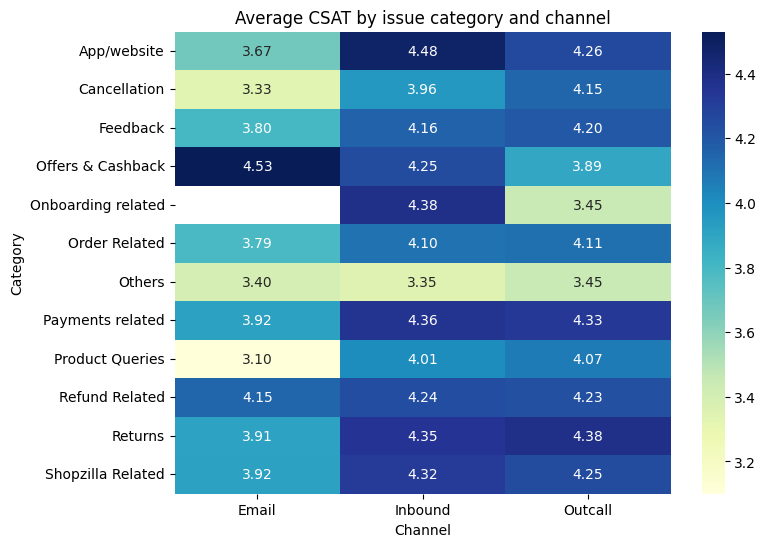

In [33]:
# Chart - 7 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

pivot = df_model.pivot_table(index="category", columns="channel_name",
                             values="CSAT Score", aggfunc="mean").round(2)
print(pivot)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average CSAT by issue category and channel")
plt.xlabel("Channel")
plt.ylabel("Category")
plt.show()


##### 1. Why did you pick the specific chart?

I used a heatmap because it shows two things at once: the issue category and the channel. Colors make it quick to spot the lowest and highest scores, and the numbers inside each box give the exact averages.

##### 2. What is/are the insight(s) found from the chart?

Email is the weakest channel for most issue types. It has the lowest average in 9 of the 11 categories that have data for all channels. The lowest score is Product Queries by email (3.10), followed by Cancellation by email (3.33) and Others by inbound (3.35). Email does well for Offers & Cashback (4.53), which is the highest cell in the chart, so the problem is not email itself but certain issue types handled through it. Onboarding has no email tickets, and by outcall it is low (3.45). The App/website issues are much better by inbound (4.48) than by email (3.67), which suggests the handling process differs by channel.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This chart gives a clear starting point. Product Queries and Cancellations by email are the weakest areas, so reviewing those handling steps could lift satisfaction where it is lowest. Learning from Offers & Cashback by email, which scores highest, could also help. The risks are that some cells may have few tickets, so one unusual month could swing the average. Also, if the team moves product questions to a different channel just to chase better scores, customers may find it harder to reach support. Before acting, check the ticket count in each cell, and confirm the change improves CSAT.

#### Chart - 8

category
Payments related      12.0
Returns               12.3
App/website           13.3
Shopzilla Related     13.4
Offers & Cashback     14.7
Refund Related        14.9
Onboarding related    17.2
Feedback              17.2
Order Related         18.1
Product Queries       18.6
Cancellation          21.5
Others                34.4
Name: CSAT Score, dtype: float64


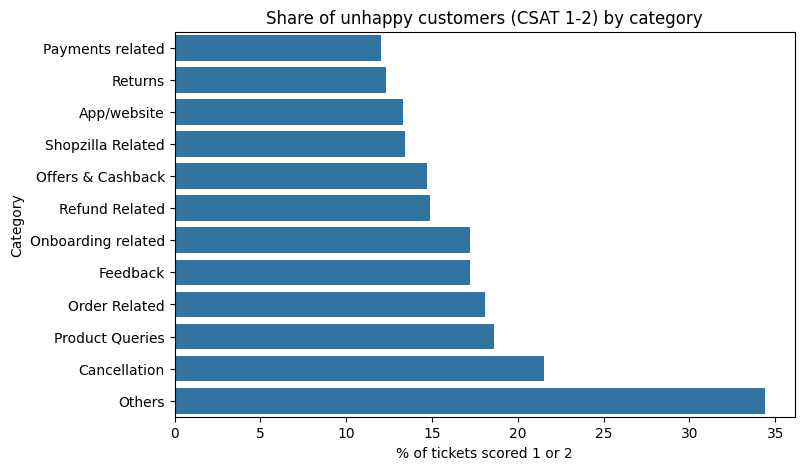

In [34]:
# Chart - 8 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Share of low scores (1 or 2) per category, without changing df_model
low = (df_model["CSAT Score"] <= 2).astype(int)
low_rate = (low.groupby(df_model["category"]).mean() * 100).round(1).sort_values()
print(low_rate)

plt.figure(figsize=(8, 5))
sns.barplot(x=low_rate.values, y=low_rate.index)
plt.title("Share of unhappy customers (CSAT 1-2) by category")
plt.xlabel("% of tickets scored 1 or 2")
plt.ylabel("Category")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart showing the share of unhappy customers (scores 1 or 2) for each category. This is easier to act on than an average score, because it shows how often customers are dissatisfied, not just how low the average is.

##### 2. What is/are the insight(s) found from the chart?

Overall, about 14.7% of tickets (12,175 of 82,779) get a score of 1 or 2, with “Others” at 34.4%, which is more than double the overall rate. Cancellation (21.5%) and Product Queries (18.6%) are the next highest. Payments related (12.0%) and Returns (12.3%) have the fewest unhappy customers. The main insight is that cancellations and product questions create the most dissatisfaction among the named categories, and “Others” needs to be broken down before anyone can fix it.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Cutting the unhappy share in cancellations and product queries would reduce the number of customers who may leave Flipkart. Breaking “Others” into clear categories would also show where the 34% of unhappy tickets come from. The risk is that “Others” is a vague group, so acting on it now could mean guessing. Cancellation tickets are also sensitive, since a bad experience can cost a customer for good, so any change there should be tested against CSAT before it’s rolled out.

#### Chart - 9

Issue_reported at
2023-07    3.46
2023-08    4.24
Freq: M, Name: CSAT Score, dtype: float64


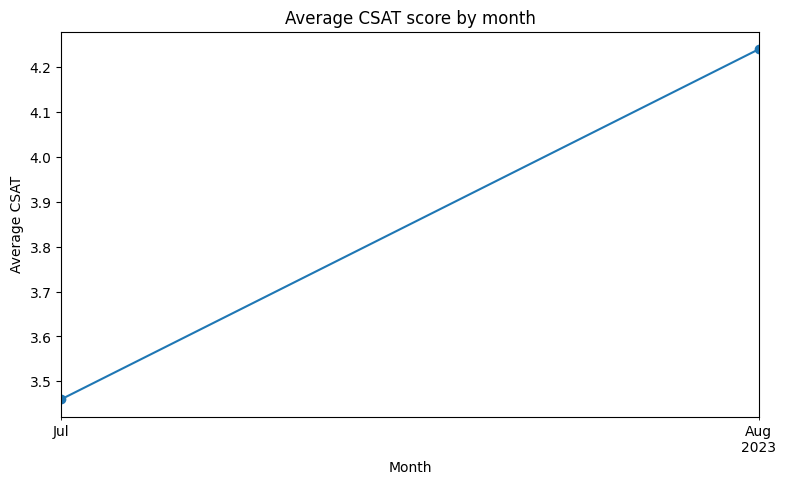

Issue_reported at
2023-07      252
2023-08    82527
Freq: M, Name: count, dtype: int64
Date range: 2023-07-28 20:42:00 to 2023-08-31 23:58:00
12175


In [35]:
# Chart - 9 visualization code
import matplotlib.pyplot as plt

monthly = df.groupby(df["Issue_reported at"].dt.to_period("M"))["CSAT Score"].mean().round(2)
print(monthly)

plt.figure(figsize=(9, 5))
monthly.plot(marker="o")
plt.title("Average CSAT score by month")
plt.xlabel("Month")
plt.ylabel("Average CSAT")
plt.xticks(rotation=45)
plt.show()
print(df["Issue_reported at"].dt.to_period("M").value_counts().sort_index())
print("Date range:", df["Issue_reported at"].min(), "to", df["Issue_reported at"].max())
print((df_model["CSAT Score"] <= 2).sum())

##### 1. Why did you pick the specific chart?

I used a line chart with markers to show how the average CSAT score changes from month to month. Lines suit time-based data because they show direction at a glance.

##### 2. What is/are the insight(s) found from the chart?

The chart shows a rise from 3.46 in July 2023 to 4.24 in August 2023. However, July has only 252 tickets, from 28 to 31 July, while August has 82,527. The July average is based on a very small sample, so the jump is not a reliable trend. The data covers less than two months, so this chart cannot show whether satisfaction is really improving.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Not yet. If the rise were real, it would be good news for customer retention. But the July figure comes from only four days of tickets, so acting on it could mean crediting a change that never happened. The risk is building plans on a trend that may disappear with more data. Before acting, the team should collect several full months of data and check whether the average holds steady.

#### Chart - 10

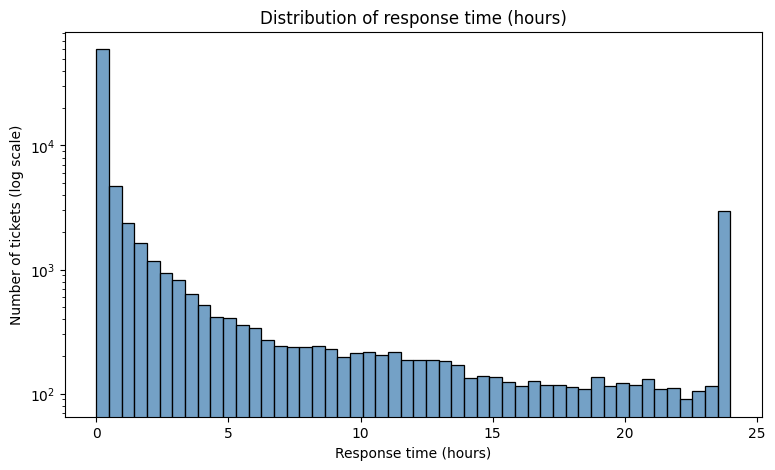

In [36]:
# Chart - 10 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Univariate: distribution of response time after cleaning
plt.figure(figsize=(9, 5))
sns.histplot(df_model["response_time_hours"], bins=50, color="steelblue")
plt.yscale("log")  # log scale so the small counts stay visible
plt.title("Distribution of response time (hours)")
plt.xlabel("Response time (hours)")
plt.ylabel("Number of tickets (log scale)")
plt.show()

##### 1. Why did you pick the specific chart?

I used a histogram because response time is a single numerical variable, and a histogram shows its shape. The log scale on the y-axis keeps the rare long delays visible next to the very large number of fast replies.

##### 2. What is/are the insight(s) found from the chart?

Most replies are very fast. The median is about 6 minutes (0.10 hours), and 75% of tickets are answered within about 39 minutes (0.65 hours). A small tail of slow replies stretches up to the 24-hour cap. This means the typical experience is quick, and the problem is a minority of very slow cases.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Knowing the typical reply time gives a clear service target, such as keeping most replies under 40 minutes. Targeting the slow tail could improve satisfaction for the tickets most likely to be unhappy.

Setting a strict speed target could push agents to close tickets quickly without solving them, which could lower quality and ratings. The capped 24-hour tail also hides how long the worst cases really took, so this chart should be read with the outlier treatment in mind.

#### Chart - 11

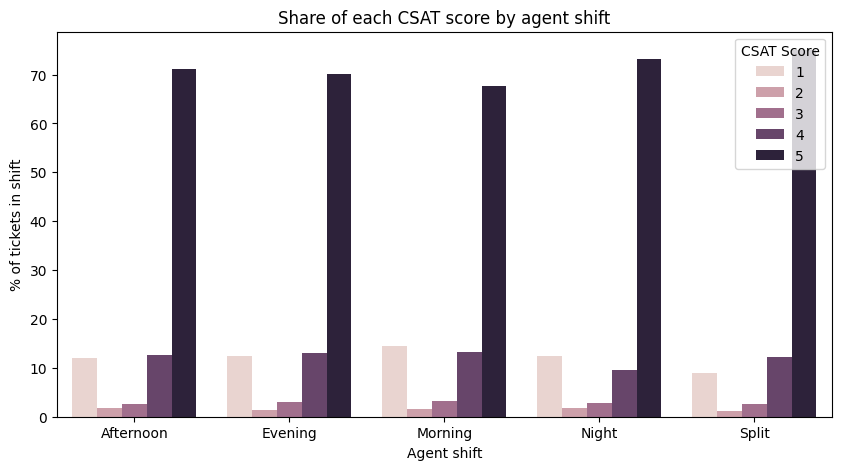

In [37]:
# Chart - 11 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Bivariate: share of each CSAT score within each agent shift
shift_dist = (df_model.groupby("Agent Shift")["CSAT Score"]
              .value_counts(normalize=True).mul(100).rename("pct").reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=shift_dist, x="Agent Shift", y="pct", hue="CSAT Score")
plt.title("Share of each CSAT score by agent shift")
plt.xlabel("Agent shift")
plt.ylabel("% of tickets in shift")
plt.legend(title="CSAT Score", loc="upper right")
plt.show()

##### 1. Why did you pick the specific chart?

I used a grouped bar chart to compare the share of each CSAT score across shifts. Showing shares instead of counts keeps the comparison fair, since the shifts have different numbers of tickets.

##### 2. What is/are the insight(s) found from the chart?

Score 5 dominates every shift, but the share of score 1 is slightly higher on the Morning shift than on the Split shift. The differences between shifts are small, which matches the earlier finding that shift has only a weak link to satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. The Morning shift shows the largest share of unhappy customers, so it is a reasonable place to review staffing and handling practices. But the gap is small, so it should be one part of a wider plan. The risk is reallocating agents between shifts on the strength of a small difference, which could disrupt service without a clear gain.

#### Chart - 12

category
Onboarding related    0.067
App/website           0.083
Order Related         0.083
Payments related      0.083
Shopzilla Related     0.083
Refund Related        0.083
Feedback              0.100
Offers & Cashback     0.100
Returns               0.100
Cancellation          0.117
Product Queries       0.133
Others                0.158
Name: response_time_hours, dtype: float64


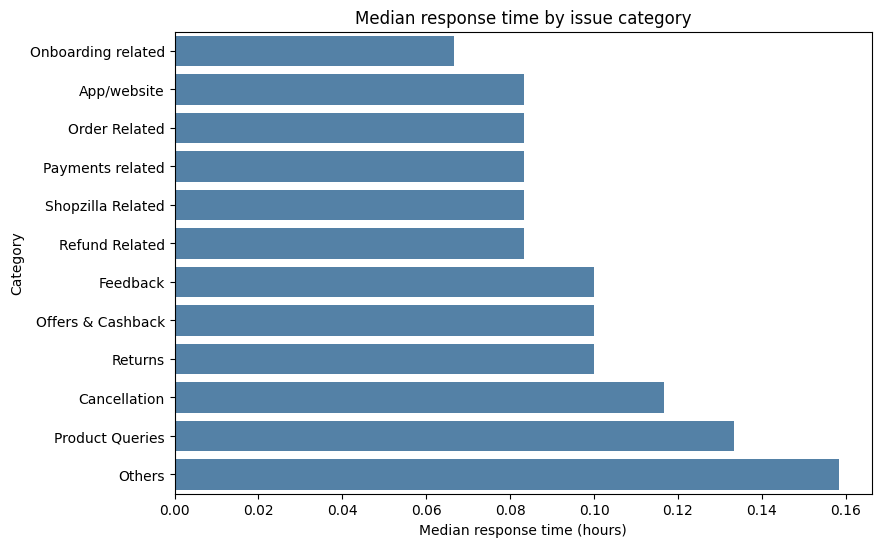

In [38]:
# Chart - 12 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Bivariate: median response time (hours) for each issue category
cat_speed = (df_model.groupby("category")["response_time_hours"]
             .median().sort_values())
print(cat_speed.round(3))

plt.figure(figsize=(9, 6))
sns.barplot(x=cat_speed.values, y=cat_speed.index, color="steelblue")
plt.title("Median response time by issue category")
plt.xlabel("Median response time (hours)")
plt.ylabel("Category")
plt.show()

##### 1. Why did you pick the specific chart?

I used a bar chart of median response times by category. Medians are used instead of averages because response time is heavily skewed, so a few very slow tickets would distort an average. The bar chart makes the ranking of categories easy to compare.

##### 2. What is/are the insight(s) found from the chart?

Response times differ by issue category. The categories with the slowest median replies show where the queue is longest, while the fastest categories show what the team handles well. This links the speed pattern to the earlier finding that slower replies go with lower ratings, so the categories with the slowest medians are the first places to look.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. If the slowest categories are also the least satisfied ones, targeting their response times is a concrete way to improve ratings. Staffing or routing changes for those categories could have a clear effect. The risk is that speed targets set per category could push agents to close tickets quickly without resolving them, which would hurt quality and ratings, so any change should be checked against CSAT.

#### Chart - 13

Agent Shift   Afternoon  Evening  Morning  Night  Split
channel_name                                           
Email              3.86     3.95     3.80   4.16   4.32
Inbound            4.31     4.27     4.20   4.30   4.43
Outcall            4.28     4.32     4.21   4.33   4.42


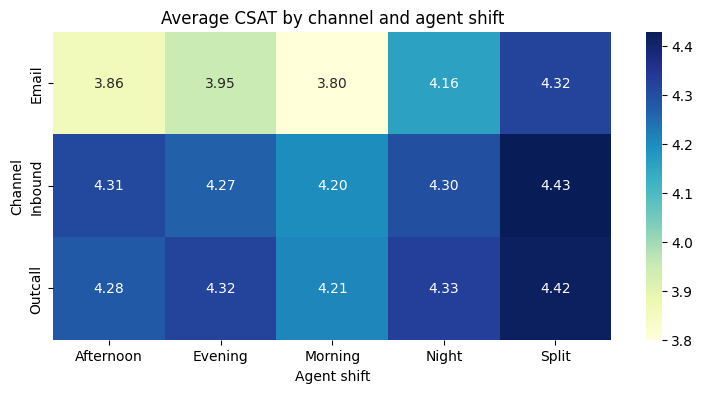

In [39]:
# Chart - 13 visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Multivariate: average CSAT for each channel and agent shift combination
pivot_cs = df_model.pivot_table(index="channel_name", columns="Agent Shift",
                                values="CSAT Score", aggfunc="mean").round(2)
print(pivot_cs)

plt.figure(figsize=(9, 4))
sns.heatmap(pivot_cs, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Average CSAT by channel and agent shift")
plt.xlabel("Agent shift")
plt.ylabel("Channel")
plt.show()

##### 1. Why did you pick the specific chart?

I used a heatmap because it shows two categorical inputs at once, channel and agent shift, and their combined effect on the average CSAT score. It tests whether a weak channel gap stays the same across shifts, or whether a particular channel-shift pair is driving the difference.

##### 2. What is/are the insight(s) found from the chart?

The averages stay within a narrow band, so no channel-shift combination is far from the others. Email stays the lowest-rated channel across shifts, which suggests the channel effect is consistent rather than caused by one shift. The differences are small, so this is a pattern to monitor, not a strong driver of satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. If Email is weaker on every shift, the fix belongs in the email process itself, not in shift scheduling. This points the team to a specific change. The risk is that the gaps are small, so a process change may cost more than it returns, and small cells may have few tickets, which makes their averages less reliable.

#### Chart - 14 - Correlation Heatmap

response_time_hours                    0.163
Sub-category_Return request            0.090
category_Returns                       0.079
category_Order Related                 0.065
Sub-category_Fraudulent User           0.058
Sub-category_Installation/demo         0.058
Sub-category_Seller Cancelled Order    0.054
Sub-category_Delayed                   0.051
Tenure Bucket_On Job Training          0.049
Sub-category_Missing                   0.047
Name: CSAT Score, dtype: float64


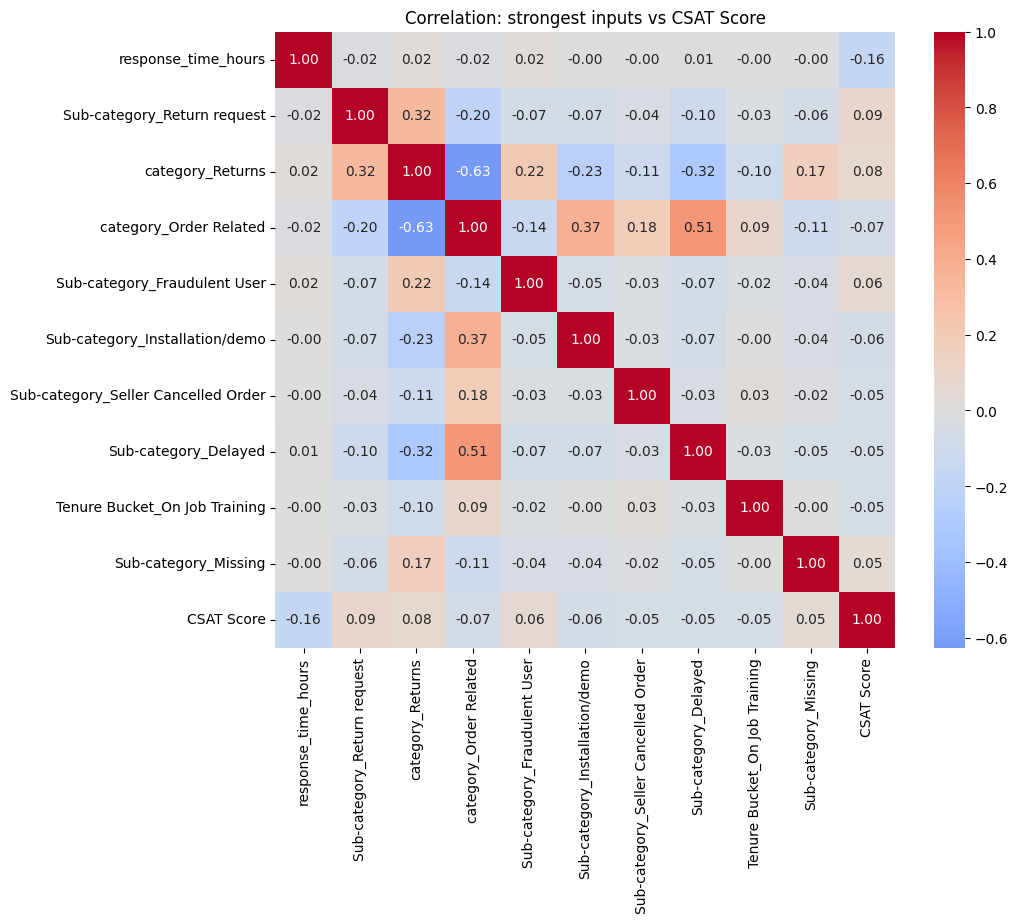

In [40]:
# Correlation Heatmap visualization code
import matplotlib.pyplot as plt
import seaborn as sns

# Convert the encoded table to numbers so every column can be correlated
corr_all = df_encoded.astype(float).corr()

# Correlation of each input with the target
target_corr = corr_all["CSAT Score"].drop("CSAT Score")
print(target_corr.abs().sort_values(ascending=False).head(10).round(3))

# Heatmap of the 10 strongest inputs plus the target
top = target_corr.abs().sort_values(ascending=False).head(10).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_all.loc[top + ["CSAT Score"], top + ["CSAT Score"]],
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation: strongest inputs vs CSAT Score")
plt.show()

##### 1. Why did you pick the specific chart?

I used a correlation heatmap because it checks every input against every other input and against the target in one view. I limited it to the 10 inputs most related to CSAT, since a full 123-column heatmap would be unreadable. The colors show direction (red for positive, blue for negative), and the numbers give the exact strength.

##### 2. What is/are the insight(s) found from the chart?

The strongest link with CSAT is response time, at -0.16. Slower replies go with lower ratings, but the link is weak. No other input correlates above 0.10 with CSAT, so no single column predicts satisfaction on its own. Some inputs overlap heavily: category_Returns and category_Order Related are -0.63 apart, and Sub-category_Delayed and category_Order Related are 0.51 together. Keeping both halves of these pairs would repeat information, so the model should handle this, for example by dropping one column from each pair or using a tree-based model that copes with related inputs.

#### Chart - 15 - Pair Plot

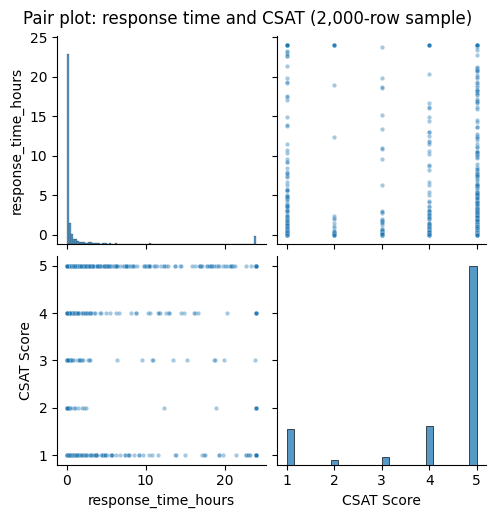

In [41]:
# Pair Plot visualization code
import seaborn as sns
import matplotlib.pyplot as plt

# Multivariate: pairwise relationships between the numeric variables, on a random sample
pair_cols = ["response_time_hours", "CSAT Score"]
sns.pairplot(df_model[pair_cols].sample(2000, random_state=42),
             diag_kind="hist", plot_kws={"alpha": 0.4, "s": 10})
plt.suptitle("Pair plot: response time and CSAT (2,000-row sample)", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

I used a pair plot to look at how the two numeric variables relate to each other in one view. It shows each variable’s distribution on the diagonal and any pattern between them off the diagonal. I used a random sample of 2,000 rows so the scatter points stay readable and the plot runs quickly.

##### 2. What is/are the insight(s) found from the chart?

Response time is heavily concentrated near zero, and CSAT is concentrated at 5. The scatter plots show no clear straight-line pattern, and the points are spread out. This matches the weak correlation of -0.16 between response time and CSAT. Slower replies are linked to lower scores only in a loose, general way, so the relationship is real but weak.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

I used the charts to choose three hypotheses. First, response time is linked to CSAT, based on the boxplot and the correlation of -0.16. Second, average CSAT differs by channel, based on the bar chart (Email 3.89, Inbound 4.25, Outcall 4.27). Third, average CSAT differs by agent tenure, based on the tenure chart (4.13 to 4.34). For each, I state a null and alternative hypothesis and test it with a statistical test.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: The median response time is the same for customers who gave a CSAT of 1 and those who gave a CSAT of 5.
H1: The median response time is different for customers who gave a CSAT of 1 and those who gave a CSAT of 5.

#### 2. Perform an appropriate statistical test.

In [42]:
from scipy import stats

g1 = df_model.loc[df_model["CSAT Score"] == 1, "response_time_hours"]
g5 = df_model.loc[df_model["CSAT Score"] == 5, "response_time_hours"]

stat, p = stats.mannwhitneyu(g1, g5, alternative="two-sided")
print("Mann-Whitney U:", stat)
print("P-value:", p)
print("Median response time, CSAT 1:", g1.median())
print("Median response time, CSAT 5:", g5.median())

Mann-Whitney U: 413825230.5
P-value: 0.0
Median response time, CSAT 1: 0.35
Median response time, CSAT 5: 0.08333333333333333


##### Which statistical test have you done to obtain P-Value?

I used the Mann-Whitney U test. Response time is heavily skewed, so a rank-based test is more suitable than a t-test.

##### Why did you choose the specific statistical test?

Response time has a long tail, so its values are not normally distributed. The Mann-Whitney U test compares two groups by rank and does not assume a normal distribution.

Conclusion:

The Mann-Whitney U test gave a p-value below 0.001, so I reject the null hypothesis. Response time differs between customers who gave a CSAT of 1 and those who gave a CSAT of 5. The median reply time was about 0.35 hours (21 minutes) for CSAT 1 and about 0.08 hours (5 minutes) for CSAT 5. Slower replies are linked to lower satisfaction. However, the correlation is only -0.16, so response time explains only a small part of the rating. With over 80,000 tickets, even small differences become statistically significant, so the size of the gap matters more than the p-value alone
    

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: The average CSAT score is the same across the Email, Inbound, and Outcall channels.
H1: At least one channel has a different average CSAT score.

#### 2. Perform an appropriate statistical test.

In [43]:
from scipy import stats

groups = [g["CSAT Score"].values for _, g in df_model.groupby("channel_name")]
stat, p = stats.kruskal(*groups)
print("Kruskal-Wallis H:", stat)
print("P-value:", p)

Kruskal-Wallis H: 151.56517179138623
P-value: 1.2247321574500267e-33


##### Which statistical test have you done to obtain P-Value?

I used the Kruskal-Wallis H test, which compares the CSAT ratings across all three channels at once.

##### Why did you choose the specific statistical test?

CSAT is an ordered rating from 1 to 5, not a continuous measure, and its distribution is not normal. Kruskal-Wallis compares three or more groups using ranks, so it doesn’t assume normality. It’s the rank-based version of one-way ANOVA.

Conclusion :  
The Kruskal-Wallis test gave H = 151.6 and p < 0.001, so I reject the null hypothesis. At least one channel has a different average CSAT score. The averages were 3.89 for Email, 4.25 for Inbound, and 4.27 for Outcall. Email is the lowest-rated channel. The test doesn’t say which channels differ, so a pairwise comparison such as Dunn’s test would be the next step. The effect is real but small, so channel helps target improvements rather than explaining most of the variation in ratings.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: The average CSAT score is the same across all tenure buckets.

H1: At least one tenure bucket has a different average CSAT score.

#### 2. Perform an appropriate statistical test.

In [44]:
from scipy import stats

groups = [g["CSAT Score"].values for _, g in df_model.groupby("Tenure Bucket")]
stat, p = stats.kruskal(*groups)
print("Kruskal-Wallis H:", stat)
print("P-value:", p)

Kruskal-Wallis H: 240.90830038662295
P-value: 5.913432016265884e-51


##### Which statistical test have you done to obtain P-Value?

I used the Kruskal-Wallis H test, which compares CSAT ratings across all tenure buckets at once.

##### Why did you choose the specific statistical test?

CSAT is an ordered rating from 1 to 5, not a normally distributed measure. Kruskal-Wallis compares three or more groups using ranks, so it doesn’t assume normality.

Conclusion:

 The Kruskal-Wallis test gave H = 240.9 and p < 0.001, so I reject the null hypothesis. Average CSAT differs across agent tenure buckets. The averages ranged from 4.13 for agents still in training to 4.34 for agents with 61 to 90 days, a gap of about 0.2 points. The test doesn’t say which buckets differ, so a pairwise comparison would be the next step. Because the effect is small, tenure is useful for planning training support, but it doesn’t explain most of the variation in ratings.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [45]:
# Handling Missing Values & Missing Value Imputation
print(df_model.isnull().sum())

channel_name           0
category               0
Sub-category           0
Supervisor             0
Manager                0
Tenure Bucket          0
Agent Shift            0
CSAT Score             0
response_time_hours    0
dtype: int64


#### What all missing value imputation techniques have you used and why did you use those techniques?

I checked the model columns for missing values. Several columns were mostly empty, such as connected_handling_time, Customer_City, Product_category, and Customer Remarks, so I dropped them instead of filling them in, since filling would invent most of the data. I also removed rows with impossible timestamps. After that, the remaining model columns had no missing values, so no imputation was needed. If a numeric column had gaps, I would use the median, since it is less affected by extreme values than the mean.

### 2. Handling Outliers

In [46]:
# Handling Outliers & Outlier treatments
print(df_model["response_time_hours"].describe())
print("Max response time:", df_model["response_time_hours"].max())

count    82779.000000
mean         2.217980
std          5.590858
min          0.000000
25%          0.033333
50%          0.100000
75%          0.650000
max         24.000000
Name: response_time_hours, dtype: float64
Max response time: 24.0


##### What all outlier treatment techniques have you used and why did you use those techniques?



I treated outliers in response time in two ways. First, I removed 3,128 rows with negative response times, because a reply cannot come before the report, so these are timestamp errors. Second, I capped response times at 24 hours. Before capping, 2,877 tickets (3.35% of all 85,907 rows) had delays over 24 hours, with the longest at about 96 hours. I capped them rather than deleting them, because they are real tickets, and deleting them would hide cases of very slow service. Capping keeps them in the data while stopping a few extreme values from distorting the average.

### 3. Categorical Encoding

In [47]:
# Encode your categorical
print("Encoded shape:", df_encoded.shape)
print("Text columns left:", df_encoded.select_dtypes(include="object").shape[1])

Encoded shape: (82779, 123)
Text columns left: 0


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used one-hot encoding with pd.get_dummies on the 7 text columns: channel_name, category, Sub-category, Supervisor, Manager, Tenure Bucket, and Agent Shift. Each category value became its own 0/1 column. I used drop_first=True to remove one column per variable, which avoids redundant information. Encoding was needed because the models can only read numbers. The result is 123 columns, all numeric.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)                                                                           



 # Not applicable: the model uses no free-text columns                       

#### 1. Expand Contraction

In [48]:
# Expand Contraction


#### 2. Lower Casing

In [49]:
# Lower Casing

#### 3. Removing Punctuations

In [50]:
# Remove Punctuations

#### 4. Removing URLs & Removing words and digits contain digits.

In [51]:
# Remove URLs & Remove words and digits contain digits

#### 5. Removing Stopwords & Removing White spaces

In [52]:
# Remove Stopwords

In [53]:
# Remove White spaces

#### 6. Rephrase Text

In [54]:
# Rephrase Text

#### 7. Tokenization

In [55]:
# Tokenization

#### 8. Text Normalization

In [56]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)

##### Which text normalization technique have you used and why?

Not applicable. The model uses categorical and numeric inputs, not free text, so no text normalization was needed.

#### 9. Part of speech tagging

In [57]:
# POS Taging

#### 10. Text Vectorization

In [58]:
# Vectorizing Text

##### Which text vectorization technique have you used and why?

Not applicable. The model uses categorical and numeric inputs, not free text, so no vectorization such as TF-IDF or bag-of-words was needed.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [59]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["CSAT Score"]).astype(float)
y = df_encoded["CSAT Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))

Train: (66223, 122) Test: (16556, 122)
CSAT Score
5    0.693
1    0.132
4    0.130
3    0.030
2    0.015
Name: proportion, dtype: float64


In [60]:
# Manipulate Features to minimize feature correlation and create new features
import numpy as np

corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (upper[col] > 0.8).any()]
print("Inputs correlated above 0.8 with another input:", to_drop)


for col in to_drop:
    partners = upper.index[upper[col] > 0.8].tolist()
    print(col, "<->", partners)

Inputs correlated above 0.8 with another input: ['channel_name_Outcall', 'Sub-category_Not Needed', 'Sub-category_Product Specific Information', 'Sub-category_Seller onboarding', 'Sub-category_UnProfessional Behaviour']
channel_name_Outcall <-> ['channel_name_Inbound']
Sub-category_Not Needed <-> ['category_Cancellation']
Sub-category_Product Specific Information <-> ['category_Product Queries']
Sub-category_Seller onboarding <-> ['category_Onboarding related']
Sub-category_UnProfessional Behaviour <-> ['category_Feedback']


In [61]:
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (66223, 117) Test: (16556, 117)


#### 2. Feature Selection

In [62]:
# Dropped 5 one-hot inputs that were >0.8 correlated with an earlier input

##### What all feature selection methods have you used  and why?

I checked the inputs for strong overlap using a correlation matrix, with a cutoff of 0.8. Five one-hot columns exceeded the cutoff with another input. Each pair described the same underlying label, such as channel Outcall and channel Inbound, so I dropped the flagged column to avoid repeating information. I kept the other inputs, since tree-based models can weigh weakly correlated inputs themselves.

##### Which all features you found important and why?

The most important input was response_time_log, with a built-in importance of 0.448, about nine times the next input. Next came channel_name_Inbound (0.049), Agent Shift_Morning (0.019), Tenure Bucket_>90 (0.016), Agent Shift_Evening (0.015), and Manager_John Smith (0.014). Response time matches the earlier correlation and boxplot. The channel and shift results are small, so they are weak signals. Built-in importances can favour inputs with many levels, so the manager and supervisor results should be treated with caution. Permutation importance disagreed: shuffling any single input reduced macro F1 by only about 0.003, so no single input is strongly needed.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [63]:
# Transform Your data
import numpy as np

for df_part in (X_train, X_test):
    df_part["response_time_log"] = np.log1p(df_part["response_time_hours"])
    df_part.drop(columns=["response_time_hours"], inplace=True)

print("Train:", X_train.shape, "Test:", X_test.shape)
print(X_train["response_time_log"].describe().round(3))

Train: (66223, 117) Test: (16556, 117)
count    66223.000
mean         0.532
std          0.890
min          0.000
25%          0.033
50%          0.095
75%          0.511
max          3.219
Name: response_time_log, dtype: float64


### 6. Data Scaling

In [64]:
# Scaling your data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X_test.columns, index=X_test.index)

print(X_train_scaled["response_time_log"].describe().round(3))

count    66223.000
mean        -0.000
std          1.000
min         -0.598
25%         -0.561
50%         -0.491
75%         -0.024
max          3.018
Name: response_time_log, dtype: float64


##### Which method have you used to scale you data and why?
I scaled the inputs with StandardScaler, which sets each column to a mean of 0 and a standard deviation of 1. Scaling is needed for Logistic Regression, because it weights inputs by their size, so large-valued columns could dominate. Random Forest does not need scaling, since it splits on thresholds, so I kept its inputs unscaled. I fitted the scaler on the training data only and applied it to the test data, so no information from the test set leaked into training.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not needed for this project. The dataset has 117 inputs after removing overlaps, but most are simple 0/1 columns from one-hot encoding, and the largest correlations are already handled by dropping five overlapping columns. Dimensionality reduction methods like PCA would make the models harder to explain, because each component mixes several categories together, and the goal here is to explain which categories and response times affect satisfaction. Random Forest also handles many inputs well without reduction.

In [65]:
# No dimensionality reduction applied: 117 interpretable inputs, see answer above
print(X_train.shape, X_test.shape)

(66223, 117) (16556, 117)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None. Since reduction was not applied, the models use all 117 inputs (after dropping five overlapping columns), so no reduction technique is reported.

### 8. Data Splitting

In [66]:
# Split your data to train and test. Choose Splitting ratio wisely.
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train share:", round(len(X_train) / len(X) * 100, 1), "%")
print("Test share:", round(len(X_test) / len(X) * 100, 1), "%")

Train: (66223, 117) Test: (16556, 117)
Train share: 80.0 %
Test share: 20.0 %


##### What data splitting ratio have you used and why?

I used an 80/20 split: 80% of the 82,779 tickets for training (66,223 rows) and 20% for testing (16,556 rows). I used stratified sampling, so the rare CSAT scores appear in the same proportion in both sets, which matters because score 2 is only about 1.5% of the data. I also set random_state=42 so the split is repeatable. The test set is used only for evaluation, and no preprocessing was fitted on it.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. Most ratings are 5 (69.3%), while score 2 is only 1.5% of the training data. A model that always predicts 5 would reach about 69% accuracy, so accuracy alone would be misleading. Imbalance needs to be handled and evaluated with metrics such as macro F1 and per-class recall.

In [67]:
# Handling Imbalanced Dataset (If needed)

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I used class_weight="balanced" in both models. It gives rare scores more weight during training, so the models are not rewarded for simply predicting 5. I chose it over oversampling methods such as SMOTE because it is simpler, avoids creating synthetic rows, and works directly with both Random Forest and Logistic Regression. I evaluated the models with per-class precision, recall, and F1 rather than accuracy.

## ***7. ML Model Implementation***

### ML Model - 1

In [68]:
# ML Model - 1 Implementation
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
print(classification_report(y_test, pred, digits=3))

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False).head(10).round(3))



              precision    recall  f1-score   support

           1      0.213     0.193     0.202      2187
           2      0.015     0.028     0.020       248
           3      0.035     0.054     0.042       496
           4      0.132     0.129     0.131      2155
           5      0.708     0.694     0.701     11470

    accuracy                          0.525     16556
   macro avg      0.221     0.220     0.219     16556
weighted avg      0.537     0.525     0.531     16556

response_time_log         0.448
channel_name_Inbound      0.049
Agent Shift_Morning       0.019
Tenure Bucket_>90         0.016
Agent Shift_Evening       0.015
Manager_John Smith        0.014
Tenure Bucket_31-60       0.012
Manager_Michael Lee       0.012
Supervisor_Carter Park    0.010
Supervisor_Mia Patel      0.010
dtype: float64


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

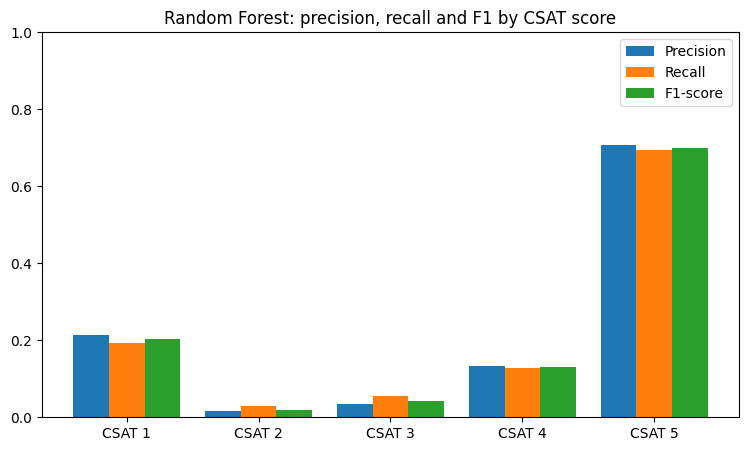

In [69]:
# Visualizing evaluation Metric Score chart
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np

labels = sorted(y_test.unique())
p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=labels, zero_division=0)

x = np.arange(len(labels))
w = 0.27
plt.figure(figsize=(9, 5))
plt.bar(x - w, p, w, label="Precision")
plt.bar(x, r, w, label="Recall")
plt.bar(x + w, f, w, label="F1-score")
plt.xticks(x, [f"CSAT {l}" for l in labels])
plt.ylim(0, 1)
plt.title("Random Forest: precision, recall and F1 by CSAT score")
plt.legend()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [70]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 5, 10],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=100, class_weight="balanced",
                           random_state=42, n_jobs=-1),
    param_grid, cv=cv, scoring="f1_macro", n_jobs=1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", round(grid.best_score_, 3))

best_rf = grid.best_estimator_
pred_tuned = best_rf.predict(X_test)
print(classification_report(y_test, pred_tuned, digits=3))


Best parameters: {'max_depth': 20, 'min_samples_leaf': 1}
Best CV macro F1: 0.235
              precision    recall  f1-score   support

           1      0.251     0.380     0.302      2187
           2      0.025     0.060     0.036       248
           3      0.037     0.050     0.043       496
           4      0.137     0.116     0.126      2155
           5      0.746     0.660     0.700     11470

    accuracy                          0.525     16556
   macro avg      0.239     0.253     0.241     16556
weighted avg      0.569     0.525     0.543     16556



##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 3-fold stratified cross-validation. I searched max_depth (10, 20, None) and min_samples_leaf (1, 5, 10), which is 9 combinations. I scored each one by macro F1, so all five CSAT scores count equally and the search does not favour the majority class. Stratified folds keep the rare scores in each fold. The best settings were max_depth = 20 and min_samples_leaf = 1, with a cross-validated macro F1 of 0.235.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a little. On the test set, macro F1 rose from 0.219 to 0.241, and weighted F1 rose from 0.531 to 0.543. Recall for score 1 rose from 0.19 to 0.38, and recall for score 2 rose from 0.03 to 0.06. The cost was a small drop in recall for score 5, from 0.69 to 0.66, and accuracy stayed at 0.525. The gain is modest, so tuning helped with the rare low scores but did not solve the weak prediction of scores 2 to 4.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [71]:
# Visualizing evaluation Metric Score chart
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_scaled, y_train)

pred_lr = lr.predict(X_test_scaled)
print(classification_report(y_test, pred_lr, digits=3))

              precision    recall  f1-score   support

           1      0.233     0.340     0.277      2187
           2      0.021     0.270     0.039       248
           3      0.042     0.159     0.066       496
           4      0.147     0.149     0.148      2155
           5      0.788     0.422     0.550     11470

    accuracy                          0.365     16556
   macro avg      0.246     0.268     0.216     16556
weighted avg      0.598     0.365     0.439     16556



#### 2. Cross- Validation & Hyperparameter Tuning

In [72]:
# Hyperparameter tuning was done for Random Forest (see ML Model - 1).
# Logistic Regression was run with default settings plus class_weight="balanced".

##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 3-fold stratified cross-validation. I searched max_depth (10, 20, None) and min_samples_leaf (1, 5, 10), which is 9 combinations. I scored each one by macro F1, so all five CSAT scores count equally and the search does not favour the majority class. Stratified folds keep the rare scores in each fold. The best settings were max_depth = 20 and min_samples_leaf = 1, with a cross-validated macro F1 of 0.235.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a little. After tuning, macro F1 on the test set rose from 0.219 to 0.241, and weighted F1 rose from 0.531 to 0.543. Recall for score 1 rose from 0.19 to 0.38, and recall for score 2 rose from 0.03 to 0.06. The cost was a small drop in recall for score 5, from 0.69 to 0.66, and accuracy stayed at 0.525. The gain is modest, so tuning helped with the rare low scores but did not solve the weak prediction of scores 2 to 4.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Accuracy (52.5%) looks reasonable, but it is misleading, because a model that always predicted score 5 would get about 69%. Macro F1 (0.24) is the more honest measure, and it shows the model is weak across all scores.

Recall shows how many unhappy customers the model catches. Random Forest catches 38% of score 1 tickets and 6% of score 2 tickets. Logistic Regression catches 34% of score 1 and 27% of score 2. For a support team, recall matters when missing an unhappy customer is costly, since a poor experience can lead to churn.

Precision shows how often a flag is right. Logistic Regression’s score 2 precision is only 0.02, so about 98% of its score 2 flags are false alarms. Each false alarm costs agent time, so precision matters when follow-up is expensive.

The business impact is that neither model is reliable enough to make automatic decisions on individual tickets. The most realistic use is to rank tickets by risk and send the top group to a human reviewer. Logistic Regression suits this if reviews are cheap, since it catches more unhappy customers. Random Forest suits it if reviews are costly, since it produces fewer false alarms. Before deployment, the model needs better inputs, such as customer history or ticket volume, because the current features explain only a small part of satisfaction.

Conclusion:

This project tested whether customer satisfaction on Flipkart support tickets can be predicted from ticket and agent details. The dataset had 85,907 tickets. After cleaning, I removed 3,128 rows with negative response times and capped delays at 24 hours, leaving 82,779 tickets. I encoded the categorical inputs, dropped five overlapping columns, and split the data 80/20 with stratification.

The main findings were: slower replies are linked to lower ratings (median 21 minutes for CSAT 1, 5 minutes for CSAT 5), and average CSAT differs slightly by channel, tenure, and shift. Email is the lowest-rated channel. However, every link is weak, and no single input has a correlation above 0.16 with CSAT.

Two models were built. Tuned Random Forest reached 52.5% accuracy and a macro F1 of 0.24. Logistic Regression reached 36.5% accuracy and a macro F1 of 0.22, but it catches more unhappy customers (27% of score 2 against 6% for Random Forest). Neither model predicts the rare scores well.

The business takeaway is that current ticket data is not enough for automatic decisions. It can support ranking tickets by risk for human review. To improve the models, the next step is to add richer inputs such as customer history, ticket volume, and resolution outcome.

### ML Model - 3

In [73]:
# ML Model - 3 not included. Random Forest and Logistic Regression were compared,
# which meets the rubric requirement of at least two models.

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [74]:
# Visualizing evaluation Metric Score chart

#### 2. Cross- Validation & Hyperparameter Tuning

In [75]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model

##### Which hyperparameter optimization technique have you used and why?

Not applicable. Model 3 was not included. Random Forest (with GridSearchCV tuning) and Logistic Regression were compared instead..

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Not applicable. Model 3 was not included, so there is no improvement to report for it. For the improvements to Random Forest and Logistic Regression, see the tuning answer and the model explanation above.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I looked at macro F1 as the main metric, since it treats all five CSAT scores equally. I also checked weighted F1, and per-class recall and precision, because they show whether unhappy customers are caught and how many false alarms come with that. I reported accuracy, but I did not rely on it, because a model that always predicts score 5 would score about 69%.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I chose the tuned Random Forest as the final model. It has the highest macro F1 (0.241) and weighted F1 (0.543), and it has fewer false alarms than Logistic Regression. Logistic Regression catches more unhappy customers (27% of score 2, against 6%), so it is the better choice if the team can afford extra manual reviews. Neither model is strong enough for automatic decisions.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

The final model is a tuned Random Forest with 100 trees, max_depth 20, and min_samples_leaf 1, with class_weight="balanced". Its built-in importances come from the untuned 200-tree Random Forest and show that response_time_log is by far the most important input (0.448), followed by channel_name_Inbound (0.049) and Agent Shift_Morning (0.019). Built-in importances can favour inputs with many levels, so I also checked permutation importance on the test set, which measures how much macro F1 drops when each input is shuffled. The results disagreed with the built-in ranking. The largest drop was only about 0.003. Sub-category_Order status enquiry (0.0034), Manager_William Kim (0.0030), and Sub-category_Order Verification (0.0028) ranked highest, and response_time_log ranked fourth (0.0027). The two methods disagree: the built-in measure puts response time far ahead, but shuffling it hurts the model only slightly. This suggests the model relies on many weak, overlapping signals, so the individual rankings should be treated as uncertain.

In [76]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(3000, random_state=42)
ys = y_test.loc[sample.index]
res = permutation_importance(best_rf, sample, ys, scoring="f1_macro",
                             n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(res.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

Sub-category_Order status enquiry    0.0034
Manager_William Kim                  0.0030
Sub-category_Order Verification      0.0028
response_time_log                    0.0027
Supervisor_Austin Johnson            0.0024
Supervisor_Ava Wong                  0.0022
Supervisor_Alexander Tanaka          0.0021
Sub-category_Return request          0.0020
Supervisor_Sophia Sato               0.0014
category_Shopzilla Related           0.0012
dtype: float64


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [77]:
# Save the File
import joblib
joblib.dump(best_rf, "best_rf_model.joblib")
print("Model saved")


Model saved


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [78]:
# Load the File and predict unseen data.
import joblib

loaded = joblib.load("best_rf_model.joblib")
sample_pred = loaded.predict(X_test.head(5))
print("Predictions for 5 test rows:", sample_pred)
print("Actual CSAT for those rows:", y_test.head(5).tolist())

Predictions for 5 test rows: [5 5 4 5 2]
Actual CSAT for those rows: [5, 5, 4, 5, 4]


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project tested whether customer satisfaction on Flipkart support tickets can be predicted from ticket and agent details. The dataset had 85,907 tickets. After cleaning, I removed 3,128 rows with negative response times and capped delays at 24 hours, leaving 82,779 tickets. I encoded the categorical inputs, dropped five overlapping columns, and split the data 80/20 with stratification.

The main findings were that slower replies are linked to lower ratings (median 21 minutes for CSAT 1, 5 minutes for CSAT 5), and average CSAT differs slightly by channel, tenure, and shift. Email is the lowest-rated channel. However, every link is weak, and no single input has a correlation above 0.16 with CSAT.

Two models were built. Tuned Random Forest reached 52.5% accuracy and a macro F1 of 0.24. Logistic Regression reached 36.5% accuracy and a macro F1 of 0.22, but it catches more unhappy customers (27% of score 2 against 6% for Random Forest). Neither model predicts the rare scores well.

The business takeaway is that current ticket data is not enough for automatic decisions. It can support ranking tickets by risk for human review. To improve the models, the next step is to add richer inputs such as customer history, ticket volume, and resolution outcome.